# Lab 2
- **Student Name**: Daniel Alejandro Castillo Martin
- **Student ID**: N10019284
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
---

## 1. Lab Objective

Investigate why the provided eight-layer `BrokenNet` fails to train on a synthetic binary classification task.

The following steps are followed to reach the final objective:

- Reproduce the failure using the unchanged starter script.
- Inspect gradients and activations to identify the cause.
- Test initialization and normalization changes in separate, controlled stages.
- Compare the loss curves to determine which change contributes most to training.

## 1. Imports and Setup

In [121]:
# Import required libraries
import pandas as pd
import numpy as np
import copy
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

# Import custom modules
from scripts.lab02_starter import BrokenNet, make_toy_classification

In [122]:
# Define device (my computer has cpu, but created validator in case it is run with cuda)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch version:', torch.__version__)
print('Device:', device)

PyTorch version: 2.14.0+cpu
Device: cpu


## 2. Baseline Without Changes

The `scripts/lab02_starter.py` file is run first. Its training procedure uses `BrokenNet`, the provided synthetic dataset, plain SGD with a learning rate of **0.1**, and **50** epochs.

The same procedure is reproduced below to store the loss at every epoch for the final comparison. No changes are made to the starter model.

In [123]:
# Set manual seeds for reproducibility
torch.manual_seed(0)

# Initialize baseline model, dataset and optimizer
baseline_model = BrokenNet()
x, y = make_toy_classification(seed = 0)
baseline_optimizer = torch.optim.SGD(baseline_model.parameters(), lr = 0.1)

In [124]:
# Create empty losses list
baseline_losses = []

# Training loop
for epoch in range(50):
    baseline_optimizer.zero_grad()

    # Compute logits and loss
    logits = baseline_model(x).squeeze(-1)
    loss = nn.functional.binary_cross_entropy_with_logits(logits, y)

    # Backward pass and optimization step
    loss.backward()
    baseline_optimizer.step()


    baseline_losses.append(loss.item())

    # Print loss every 10 epochs or final epoch
    if epoch % 10 == 0 or epoch == 49:
        print(f'epoch {epoch}   loss = {round(loss.item(), 4)}')

epoch 0   loss = 0.7037
epoch 10   loss = 0.6974
epoch 20   loss = 0.6937
epoch 30   loss = 0.6914
epoch 40   loss = 0.6901
epoch 49   loss = 0.6893


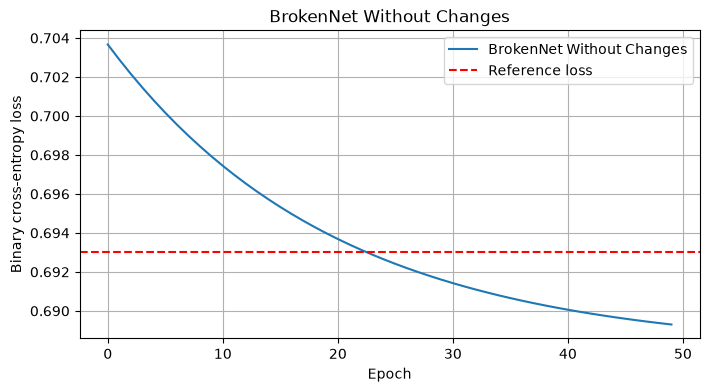

In [125]:
# Plot loss curve for baseline model
plt.figure(figsize=(8, 4))
plt.plot(range(50), baseline_losses, label = 'BrokenNet Without Changes')
plt.axhline(y = 0.693, color = 'red', linestyle = '--', label = 'Reference loss')

# Plot customizations
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.title('BrokenNet Without Changes')
plt.legend()
plt.grid()

# Show plot
plt.show()

The loss decreases from **0.7037** at epoch 0 to **0.6893** at epoch 49. Although the loss moves slightly, its final value remains close to approximately **0.693**, the binary cross-entropy associated with predictions near **0.5**. The baseline therefore shows little evidence that the model has learned to use the input features.

The loss curve confirms the failure but does not identify its cause. Gradient and activation measurements are required before testing a fix.

## 3. Diagnosis: Gradients

Another `BrokenNet` is initialized with the same random seed used in the baseline. Following one forward and backward pass, the mean absolute weight gradient is measured for each hidden layer and the output layer. The output bias gradient is also measured to determine whether the model can update a constant prediction even when its weights receive no learning signal.

In [126]:
# Set manual seeds for reproducibility
torch.manual_seed(0)

# Initialize diagnostic model
diagnostic_model = BrokenNet()
x, y = make_toy_classification(seed = 0)

# Compute logits and loss
logits = diagnostic_model(x).squeeze(-1)
diagnostic_loss = nn.functional.binary_cross_entropy_with_logits(logits, y)
diagnostic_loss.backward()

# Print initial loss
print(f'Initial loss: {round(diagnostic_loss.item(), 6)}')
# Print mean absolute gradient after one backward pass
print('\nMean absolute gradient after one backward pass:')

# Print mean absolute gradient after one backward pass
for i, layer in enumerate(diagnostic_model.hidden, start = 1):
    weight_gradient = layer.weight.grad.abs().mean().item()
    bias_gradient = layer.bias.grad.abs().mean().item()

    # Print mean absolute gradient after one backward pass for each layer
    print(f'Hidden layer {i}: weight = {round(weight_gradient, 6)} | bias = {round(bias_gradient, 6)}')

# Print mean absolute gradient after one backward pass for output layer
print(f'\nOutput layer: weight = {round(diagnostic_model.out.weight.grad.abs().mean().item(), 6)} | bias = {round(diagnostic_model.out.bias.grad.abs().mean().item(), 6)}')

Initial loss: 0.703666

Mean absolute gradient after one backward pass:
Hidden layer 1: weight = 0.0 | bias = 0.0
Hidden layer 2: weight = 0.0 | bias = 0.0
Hidden layer 3: weight = 0.0 | bias = 0.0
Hidden layer 4: weight = 0.0 | bias = 0.0
Hidden layer 5: weight = 0.0 | bias = 0.0
Hidden layer 6: weight = 0.0 | bias = 0.0
Hidden layer 7: weight = 0.0 | bias = 0.0
Hidden layer 8: weight = 0.0 | bias = 0.0

Output layer: weight = 0.0 | bias = 0.08847


## 4. Diagnosis: Activation

The gradient measurements are complemented with an activation check. For each hidden layer, the percentage of positive pre-activations and non-zero outputs after ReLU is measured across the complete synthetic dataset. This identifies the first layer, if any, whose ReLU outputs are zero for every example.

In [120]:
# Check if the activations are zero for every example
with torch.no_grad():
    activations = x

    for i, layer in enumerate(diagnostic_model.hidden, start = 1):
        pre_activations = layer(activations)
        activations = torch.relu(pre_activations)

        positive_fraction = (pre_activations > 0).float().mean().item()
        nonzero_fraction = (activations != 0).float().mean().item()

        print(f'Hidden layer {i}: positive before ReLU = {positive_fraction:.2%} | non-zero after ReLU = {nonzero_fraction:.2%}')

Hidden layer 1: positive before ReLU = 6.71% | non-zero after ReLU = 6.71%
Hidden layer 2: positive before ReLU = 0.12% | non-zero after ReLU = 0.12%
Hidden layer 3: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%
Hidden layer 4: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%
Hidden layer 5: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%
Hidden layer 6: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%
Hidden layer 7: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%
Hidden layer 8: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%


- The baseline loss decreases from **0.7037** to **0.6893** after **50** epochs but remains close to the reference value of **0.693**. The gradient check shows that the output weight receives no measurable learning signal, while its bias has a mean absolute gradient of **0.049476**.

- The activation check identifies where the input-dependent signal disappears. Only **6.76%** of the first hidden layer's outputs are nonzero; this falls to **0.17%** in layer 2 and **0.02%** in layer 3. Hidden layer 4 is the first to produce zero activations for every example, and layers 5-8 also produce only zeros. Consequently, the output depends on its bias rather than the input features. Updating that bias can slightly reduce the loss, but it cannot teach the network the classification boundary.

- The hidden layers' strongly negative initial biases **(-2.0)**, together with their weight initialization, push most pre-activations below zero. ReLU maps those values to zero and blocks gradient flow through the inactive paths. This points to an activation and initialization problem, which will be tested through controlled changes in the next stage.